# Tokenization

- Creator: Sebastian Birk (sebastian.birk@helmholtz-munich.de).
- Date of Creation: 23.04.2024
- Date of Last Modification: 28.04.2024

## 1. Setup

### 1.1 Import Libraries

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import json
import pickle
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import scanpy as sc
import scgpt as scg
import squidpy as sq
import torch
from datasets import load_from_disk
from scipy.stats import spearmanr
from scgpt.model import TransformerModel
from scgpt.tokenizer.gene_tokenizer import GeneVocab
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

from nichejepa import tokenizers
from nichejepa import utils

/home/aih/sebastian.birk/miniconda3/envs/nichejepa/lib/python3.10/site-packages/scgpt/model/model.py:21: UserWarning: flash_attn is not installed
  warnings.warn("flash_attn is not installed")
/home/aih/sebastian.birk/miniconda3/envs/nichejepa/lib/python3.10/site-packages/scgpt/model/multiomic_model.py:19: UserWarning: flash_attn is not installed
  warnings.warn("flash_attn is not installed")


### 1.2 Run Notebook Setup

In [3]:
warnings.filterwarnings("ignore")
pd.set_option('display.max_columns', None)

### 1.3 Configure Paths and Create Directories

In [4]:
# Define paths
st_data_folder_path = "../datasets/st_data" # spatially resolved transcriptomics data
st_data_bronze_folder_path = f"{st_data_folder_path}/bronze"
st_data_silver_folder_path = f"{st_data_folder_path}/silver"
st_data_gold_folder_path = f"{st_data_folder_path}/gold"
cell_gene_norm_factor_dictionary_file = "../datasets/cell_gene_norm_factors_dictionary.pkl"
neighborhood_gene_norm_factor_dictionary_file = "../datasets/neighborhood_gene_norm_factors_dictionary.pkl"
geneformer_token_dictionary_file = "../datasets/geneformer_token_dictionary.pkl"
nichejepa_token_dictionary_file = "../datasets/token_dictionary.pkl"

## 2. Tokenization

### 2.1 Create Token Dictionary

In [5]:
# Create token dict for nichejepa with cell and neighborhood tokens
with open(geneformer_token_dictionary_file, "rb") as f:
    token_dict = pickle.load(f)

new_token_dict = {
    (key + "_cell" if "ENS" in key else key): value for key, value in token_dict.items()}
new_token_dict_copy = new_token_dict.copy()
i = 0
for key in new_token_dict_copy.keys():
    if "ENS" in key:
        new_token_dict[key.replace("cell", "neighborhood")] = 25426 + i
        i += 1
del(new_token_dict_copy)

with open(nichejepa_token_dictionary_file, "wb") as file:
    pickle.dump(new_token_dict, file)

In [6]:
# Load vocab
with open(nichejepa_token_dictionary_file, "rb") as file:
    token_dict = pickle.load(file)

token_dict_reverse = {value: key for key, value in token_dict.items()}

### 2.2 Load Data

In [7]:
dataset_name = "nanostring_cosmx_human_brain"

In [8]:
adata = sc.read_h5ad(f"{st_data_silver_folder_path}/{dataset_name}.h5ad")

### 2.3 Compute Normalization Factors for Cell and Neighborhood Genes

In [42]:
gene_norm_method = "mean"

In [43]:
# Normalize cell gene counts by read depth
read_depth_norm_counts = adata.X / adata.X.sum(1).reshape(-1, 1) * 10000

if gene_norm_method == "nzmean":
    # Compute non-zero means of read-depth normalized cell gene counts
    masked_data = np.ma.masked_equal(read_depth_norm_counts, 0)
    cell_gene_norm_factor = np.ma.mean(masked_data, axis=0)
    cell_gene_norm_factor = gene_norm_factor.filled(0)
elif gene_norm_method == "mean":
    # Compute means of read-depth normalized cell gene counts
    cell_gene_norm_factor = np.mean(read_depth_norm_counts, axis=0)

# Normalize read-depth normalized cell gene counts by gene norm factor
norm_counts = read_depth_norm_counts / cell_gene_norm_factor.reshape(1, -1)

In [44]:
# Normalize neighborhood gene counts by read depth
read_depth_norm_counts_neighborhood = (adata.layers["counts_neighborhood"] /
                                       adata.layers["counts_neighborhood"].sum(1).reshape(-1, 1)
                                       * 10000)

if gene_norm_method == "nzmean":
    # Compute non-zero means of read-depth normalized neighborhood gene counts
    masked_data = np.ma.masked_equal(read_depth_norm_counts_neighborhood, 0)
    neighborhood_gene_norm_factor = np.ma.mean(masked_data, axis=0)
    neighborhood_gene_norm_factor = gene_norm_factor.filled(0)
elif gene_norm_method == "mean":
    # Compute means of read-depth normalized neighborhood gene counts
    neighborhood_gene_norm_factor = np.mean(read_depth_norm_counts_neighborhood, axis=0)

# Normalize read-depth normalized neighborhood gene counts by gene norm factor
norm_counts_neighborhood = (read_depth_norm_counts_neighborhood /
                            neighborhood_gene_norm_factor.reshape(1, -1))

In [46]:
# Create norm factor dictionary for tokenizer
cell_gene_norm_factor_dict = {}
neighborhood_gene_norm_factor_dict = {}

for gene, cell_gene_norm_factor, neighborhood_gene_norm_factor in zip(adata.var["ensembl_id"].values, cell_gene_norm_factor, neighborhood_gene_norm_factor):
    cell_gene_norm_factor_dict[gene] = cell_gene_norm_factor
    neighborhood_gene_norm_factor_dict[gene] = neighborhood_gene_norm_factor

In [47]:
# Store dictionary
with open(cell_gene_norm_factor_dictionary_file, "wb") as file:
    pickle.dump(cell_gene_norm_factor_dict, file)

with open(neighborhood_gene_norm_factor_dictionary_file, "wb") as file:
    pickle.dump(neighborhood_gene_norm_factor_dict, file)

### 2.4 Run Tokenizer

In [5]:
tk = tokenizers.STRankTokenizer(
    cell_gene_mean_file=cell_gene_norm_factor_dictionary_file,
    neighborhood_gene_mean_file=neighborhood_gene_norm_factor_dictionary_file,
    token_dictionary_file=nichejepa_token_dictionary_file,
    custom_attr_name_dict={"cell_type": "cell_types",
                           "niche_type": "niche_types"})

In [9]:
tk.tokenize_data(input_directory=st_data_silver_folder_path,
                 output_directory=st_data_gold_folder_path,
                 output_file_prefix=dataset_name)

Tokenizing '../datasets/st_data/silver/nanostring_cosmx_human_brain.h5ad'...
'../datasets/st_data/silver/nanostring_cosmx_human_brain.h5ad' has no column 'filter_pass'; tokenizing all cells.
Creating Hugging Face dataset...


Map:   0%|          | 0/188686 [00:00<?, ? examples/s]

Saving the dataset (0/7 shards):   0%|          | 0/188686 [00:00<?, ? examples/s]

### 2.5 Evaluate Tokenizer

In [10]:
# Load tokenized dataset
tokenized_data_folder_path = f"{st_data_gold_folder_path}/{dataset_name}.dataset"
dataset = load_from_disk(tokenized_data_folder_path, keep_in_memory=True)

#### 2.5.1 Neighborhood Ranking

In [ ]:
# Get cell and neighborhood gene token rankings
gene_token_ranking = np.array(dataset["input_ids"])
adata.obsm["cell_gene_token_ranking"] = gene_token_ranking[:, :1024]
adata.obsm["neighborhood_gene_token_ranking"] = gene_token_ranking[:, 1024:]

In [ ]:
len(dataset["input_ids"])

In [29]:
adata.layers

Layers with keys: counts, counts_neighborhood

In [30]:
adata.layers["counts_neighborhood"]

array([[3., 1., 0., ..., 2., 0., 0.],
       [3., 1., 0., ..., 2., 0., 0.],
       [4., 1., 0., ..., 6., 2., 1.],
       ...,
       [0., 0., 1., ..., 0., 0., 0.],
       [1., 0., 1., ..., 1., 2., 0.],
       [1., 0., 1., ..., 1., 2., 0.]])

In [17]:
# Load vocab
with open(nichejepa_token_dictionary_file, "rb") as file:
    token_dict = pickle.load(file)

In [18]:
token_dict_reverse = {value: key for key, value in token_dict.items()}

In [19]:
# Sum up ranks for each neighborhood gene token
neighborhood_gene_token_rank_sums = {}

for i, row in enumerate(adata.obsm["neighborhood_gene_token_ranking"]):
    for rank, token in enumerate(row):
        if token in neighborhood_gene_token_rank_sums:
            neighborhood_gene_token_rank_sums[token] += (1024 - rank)
        else:
            neighborhood_gene_token_rank_sums[token] = (1024 - rank)

# Replace gene token by gene ensembl id
neighborhood_gene_rank_sums = {}

for key, value in token_dict.items():
    if value in neighborhood_gene_token_rank_sums:
        neighborhood_gene_rank_sums[key.replace("_neighborhood", "")] = neighborhood_gene_token_rank_sums[value]

neighborhood_gene_rank_file = f"../datasets/temp/{dataset_name}/neighborhood_gene_rank_sums.pkl"

with open(neighborhood_gene_rank_file, "wb") as file:
    pickle.dump(neighborhood_gene_rank_sums, file)

In [20]:
# Sum up ranks for each cell gene token
cell_gene_token_rank_sums = {}

for i, row in enumerate(adata.obsm["cell_gene_token_ranking"]):
    for rank, token in enumerate(row):
        if token in cell_gene_token_rank_sums:
            cell_gene_token_rank_sums[token] += (1024 - rank)
        else:
            cell_gene_token_rank_sums[token] = (1024 - rank)

# Replace gene token by gene ensembl id
cell_gene_rank_sums = {}

for key, value in token_dict.items():
    if value in cell_gene_token_rank_sums:
        cell_gene_rank_sums[key.replace("_cell", "")] = cell_gene_token_rank_sums[value]

cell_gene_rank_file = f"../datasets/temp/{dataset_name}/cell_gene_rank_sums.pkl"

with open(cell_gene_rank_file, "wb") as file:
    pickle.dump(cell_gene_rank_sums, file)

In [21]:
adata.var["neigborhood_gene_rank_sums"] = adata.var["ensembl_id"].map(neighborhood_gene_rank_sums)
adata.var["cell_gene_rank_sums"] = adata.var["ensembl_id"].map(cell_gene_rank_sums)

In [22]:
sq.gr.spatial_autocorr(adata)

In [23]:
#del(adata.var["I"])
adata.var = adata.var.join(adata.uns["moranI"][["I"]], how="left")

In [24]:
adata.var["neigborhood_gene_rank_sums"] = adata.var["neigborhood_gene_rank_sums"].fillna(0)
adata.var["cell_gene_rank_sums"] = adata.var["cell_gene_rank_sums"].fillna(0)

In [25]:
correlation, p_value = spearmanr(adata.var["neigborhood_gene_rank_sums"],
                                 adata.var["I"])
print("Pearson Correlation Coefficient:", correlation)
print("P-value:", p_value)

Pearson Correlation Coefficient: -0.6010125298285135
P-value: 0.0


In [26]:
correlation, p_value = spearmanr(adata.var["cell_gene_rank_sums"],
                                 adata.var["I"])
print("Pearson Correlation Coefficient:", correlation)
print("P-value:", p_value)

Pearson Correlation Coefficient: 0.846660620242754
P-value: 0.0


In [119]:
correlation, p_value = spearmanr(adata.var["cell_gene_rank_sums"],
                                 adata.var["neigborhood_gene_rank_sums"])
print("Pearson Correlation Coefficient:", correlation)
print("P-value:", p_value)

Pearson Correlation Coefficient: -0.8266853490979416
P-value: 0.0


In [125]:
adata.var

,ensembl_id,neigborhood_gene_rank_sums,cell_gene_rank_sums,I
A1BG,ENSG00000121410,5468132.0,35921231.0,0.077635
A2M,ENSG00000175899,14104500.0,12039668.0,0.044612
AAAS,ENSG00000094914,12692318.0,10580903.0,0.012386
AAK1,ENSG00000115977,16394022.0,14561183.0,0.121521
AAMP,ENSG00000127837,7233919.0,14321436.0,0.052804
...,...,...,...,...
ZSWIM6,ENSG00000130449,19304516.0,8767319.0,0.013095
ZWINT,ENSG00000122952,19451470.0,8046445.0,0.012322
ZYG11B,ENSG00000162378,14320904.0,12144252.0,0.058456
ZYX,ENSG00000159840,11332699.0,13145207.0,0.072496


In [141]:
adata.uns["moranI"]

,I,pval_norm,var_norm,pval_norm_fdr_bh
MBP,0.440800,0.000000,0.000001,0.000000
PLP1,0.381628,0.000000,0.000001,0.000000
MT-CO1,0.332933,0.000000,0.000001,0.000000
GFAP,0.294164,0.000000,0.000001,0.000000
SNAP25,0.285224,0.000000,0.000001,0.000000
...,...,...,...,...
TPH2,-0.002356,0.020436,0.000001,0.038195
LEMD3,-0.002471,0.015970,0.000001,0.030903
IFT172,-0.002475,0.015820,0.000001,0.030661
CAPN7,-0.002490,0.015336,0.000001,0.029848


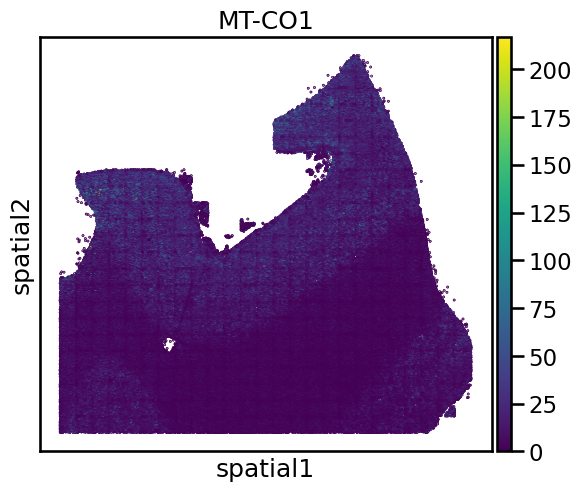

In [133]:
sq.pl.spatial_scatter(adata, color="MT-CO1", shape=None) 

In [139]:
adata.X = norm_counts

In [ ]:
len(dataset["gene_tokens_cell"][0])

In [ ]:
len(dataset["gene_tokens_neighborhood"][0])

In [ ]:
type(dataset["gene_tokens_neighborhood"])

In [ ]:
emsemblid_embedding_mapping["ENSG00000288721"].shape

In [ ]:
# Get input tokens from token ids
def get_tokens(examples):
    examples["input_tokens"] = []
    token_sequences = examples["input_ids"]
    for token_seq in token_sequences:
        tokens = []
        for token_id in token_seq:
            ensembl_id = token_dict_reverse[token_id].replace("_cell", "").replace("_neighborhood", "")
            tokens.append(emsemblid_embedding_mapping.get(ensembl_id, np.zeros(512, dtype=np.float32)))
        examples["input_tokens"].append(tokens)
    return examples

encoded_dataset = dataset.map(get_tokens, batched=True, batch_size=2)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(dataset["input_ids"], dataset["cell_type"], test_size=0.1, random_state=42, stratify=dataset["cell_type"])

In [ ]:
encoded_dataset["input_tokens"][0][:20]

In [ ]:
2+3

In [ ]:
new_folder_path = tokenized_data_folder_path.replace("nanostring_cosmx_human_brain", "nanostring_cosmx_human_brain_processed")

In [ ]:
encoded_dataset.save_to_disk(new_folder_path)

In [ ]:
encoded_dataset["input_tokens"][0]

In [ ]:
# Get scGPT gene embeddings for each gene Ensembl id
pad_token = "<pad>"
special_tokens = [pad_token, "<cls>", "<eoc>"]
n_bins = 51
pad_value = -2
n_input_bins = n_bins

model_dir = Path("../scgpt/pretrained_model")
model_config_file = model_dir / "args.json"
model_file = model_dir / "best_model.pt"
vocab_file = model_dir / "vocab.json"

vocab = GeneVocab.from_file(vocab_file)
for s in special_tokens:
    if s not in vocab:
        vocab.append_token(s)

# Retrieve model parameters from config files
with open(model_config_file, "r") as f:
    model_configs = json.load(f)
print(
    f"Resume model from {model_file}, the model args will override the "
    f"config {model_config_file}."
)
embsize = model_configs["embsize"]
nhead = model_configs["nheads"]
d_hid = model_configs["d_hid"]
nlayers = model_configs["nlayers"]
n_layers_cls = model_configs["n_layers_cls"]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

ntokens = len(vocab)  # size of vocabulary
model = TransformerModel(
    ntokens,
    embsize,
    nhead,
    d_hid,
    nlayers,
    vocab=vocab,
    pad_value=pad_value,
    n_input_bins=n_input_bins,
)

try:
    model.load_state_dict(torch.load(model_file))
    print(f"Loading all model params from {model_file}")
except:
    # only load params that are in the model and match the size
    model_dict = model.state_dict()
    pretrained_dict = torch.load(model_file)
    pretrained_dict = {
        k: v
        for k, v in pretrained_dict.items()
        if k in model_dict and v.shape == model_dict[k].shape
    }
    for k, v in pretrained_dict.items():
        print(f"Loading params {k} with shape {v.shape}")
        model_dict.update(pretrained_dict)
        model.load_state_dict(model_dict)

model.to(device)

gene2idx = vocab.get_stoi()

# Create mapping from Ensembl id to scGPT token id
metadata_df = pd.read_csv(Path("../scgpt/metadata/gene_info.csv"))

ensemblid_mapping = dict(zip(metadata_df["feature_name"], metadata_df["feature_id"]))
ensemblid2idx = {ensemblid_mapping[k]: v for k, v in gene2idx.items() if k in ensemblid_mapping}

# Retrieve the data-independent gene embeddings from scGPT
gene_ids = np.array([id for id in ensemblid2idx.values()])
gene_embeddings = model.encoder(torch.tensor(gene_ids, dtype=torch.long).to(device))
gene_embeddings = gene_embeddings.detach().cpu().numpy()

emsemblid_embedding_mapping = {}
for i, (key, val) in enumerate(ensemblid2idx.items()):
    emsemblid_embedding_mapping[key] = gene_embeddings[i, :]

In [ ]:
len(ensemblid2idx)

In [ ]:
gene_embeddings.shape

In [ ]:
emsembl_embedding_mapping

In [ ]:
gene_ids

In [ ]:
gene_embeddings

In [ ]:
# Filter on the intersection between the Immune Human HVGs found in step 1.2 and scGPT's 30+K foundation model vocab
gene_embeddings = {gene: gene_embeddings[i] for i, gene in enumerate(ensemblid2idx.keys()) if gene in adata.var.index.tolist()}
print('Retrieved gene embeddings for {} genes.'.format(len(gene_embeddings)))

In [ ]:
train_dataset = encoded_dataset['train']
test_dataset = encoded_dataset['test']

scores = dict()
for i in tqdm(range(model.config.n_layer + 1)):
    # fit linear classifier
    lr_clf = LogisticRegression(max_iter=1000)
    lr_clf.fit(train_dataset[f'features_{i}'], train_dataset['label'])
    # compute accuracy on training + test set
    training_score = lr_clf.score(train_dataset[f'features_{i}'], train_dataset['label'])
    test_score = lr_clf.score(test_dataset[f'features_{i}'], test_dataset['label'])
    scores[f'features_{i}'] = (training_score, test_score)

#### 2.5.1 Neighborhood Ranking